# 02 · Part A: who keeps coming back to hospital?

**Question:** which diabetic patients are readmitted, and how often is each patient in hospital?

**What this notebook hands to Part C (notebook 04):** for every patient, the number of hospital stays in the past 12 months (this stay plus prior stays) and an out-of-fold readmission risk score.

1. Patient profiling in SQL (DuckDB)
2. The hospital journey: A1C test → medication change → readmission
3. Three readmission models (penalized logistic regression, random forest, neural network)
4. A risk score and stays-per-year for every patient

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # scikit-learn 1.9 API-change notices
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from src.config import PROCESSED, FIGURES, SERIES, INK2, MUTED, CLASS_ORDER, style, update_results
style()

p = pd.read_parquet(PROCESSED / "patients.parquet")
con = duckdb.connect()
con.register("p", p)
BASE = p.readmit_30.mean()
print(f"{len(p):,} patients, {BASE:.1%} readmitted within 30 days")

69,987 patients, 9.0% readmitted within 30 days


## 1. Readmission rate by patient characteristic

One helper query returns, for any column: patients, % of all patients, 30-day readmission rate, and the gap to the overall rate in percentage points.

In [2]:
def rate_by(col, order=None, min_n=300):
    q = f'''
        SELECT {col} AS level, COUNT(*) AS patients,
               ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_patients,
               ROUND(100 * AVG(readmit_30), 1) AS readmit_pct
        FROM p GROUP BY 1 HAVING COUNT(*) >= {min_n}
    '''
    out = con.sql(q).df()
    out["vs_overall_pts"] = (out.readmit_pct - 100 * BASE).round(1)
    if order:
        out = out.set_index("level").reindex([o for o in order if o in set(out.level)]).reset_index()
    else:
        out = out.sort_values("readmit_pct", ascending=False)
    return out

p["prior_inpatient"] = pd.cut(p.number_inpatient, [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"]).astype(str)
p["prior_er"] = pd.cut(p.number_emergency, [-1, 0, 1, 100], labels=["0", "1", "2+"]).astype(str)
p["los_band"] = pd.cut(p.time_in_hospital, [0, 2, 4, 7, 14], labels=["1-2 days", "3-4 days", "5-7 days", "8-14 days"]).astype(str)
p["age_band"] = p.age_band.astype(str)
con.register("p", p)

dims = {
    "Prior hospital stays (past year)": rate_by("prior_inpatient", ["0", "1", "2", "3+"]),
    "Discharged to": rate_by("discharge_to"),
    "Primary diagnosis": rate_by("diag_1_group"),
    "Age": rate_by("age_band", ["<40", "40-49", "50-59", "60-69", "70-79", "80+"]),
    "Length of stay": rate_by("los_band", ["1-2 days", "3-4 days", "5-7 days", "8-14 days"]),
    "A1C test": rate_by("A1Cresult", ["Not tested", "Norm", ">7", ">8"]),
    "Admitting specialty": rate_by("specialty"),
}
dims["Prior hospital stays (past year)"]

,level,patients,pct_of_patients,readmit_pct,vs_overall_pts
0,0,61792,88.3,8.1,-0.9
1,1,5798,8.3,12.9,3.9
2,2,1501,2.1,18.5,9.5
3,3+,896,1.3,26.5,17.5


In [3]:
for name in ["Discharged to", "Primary diagnosis", "Admitting specialty"]:
    print("\n" + name); display(dims[name])


Discharged to


,level,patients,pct_of_patients,readmit_pct,vs_overall_pts
2,Skilled nursing / care facility,11940,17.1,15.1,6.1
4,Transferred to another hospital,1541,2.2,13.8,4.8
0,Other / unknown,3413,4.9,10.3,1.3
3,Home with home health,8364,12.0,9.5,0.5
5,Left against medical advice,409,0.6,9.5,0.5
1,Home,44320,63.3,6.9,-2.1



Primary diagnosis


,level,patients,pct_of_patients,readmit_pct,vs_overall_pts
4,Injury,4694,6.7,10.8,1.8
0,Circulatory,21389,30.6,9.7,0.7
1,Neoplasms,2538,3.6,9.1,0.1
3,Diabetes,5748,8.2,9.1,0.1
5,Genitourinary,3441,4.9,9.0,0.0
7,Other,12134,17.3,9.0,0.0
8,Musculoskeletal,4064,5.8,8.4,-0.6
2,Digestive,6488,9.3,8.0,-1.0
6,Respiratory,9491,13.6,7.3,-1.7



Admitting specialty


,level,patients,pct_of_patients,readmit_pct,vs_overall_pts
5,Psychiatry,613,0.9,11.1,2.1
10,Nephrology,797,1.1,11.0,2.0
7,Internal medicine,10641,15.2,9.8,0.8
3,Family / general practice,4978,7.1,9.7,0.7
2,Pulmonology,637,0.9,9.4,0.4
6,Unknown,33652,48.1,9.2,0.2
1,Orthopedics,2169,3.1,8.3,-0.7
4,Other specialty,2763,3.9,8.3,-0.7
8,Surgery,3685,5.3,8.0,-1.0
9,Emergency / trauma,4393,6.3,7.8,-1.2


**What stands out**

- **Prior hospital stays** are by far the strongest signal: patients with 3+ stays in the past year are readmitted at 26.5%, more than 3× the 8.1% for patients with none.
- **Discharge to a skilled nursing or care facility** (15.1%) carries more than twice the rate of discharge home (6.9%). These are sicker, frailer patients.
- **The primary diagnosis matters much less than I expected:** every group sits within 2 points of the 9.0% average. What predicts a return is the patient's history and where they go next, not why they came in.

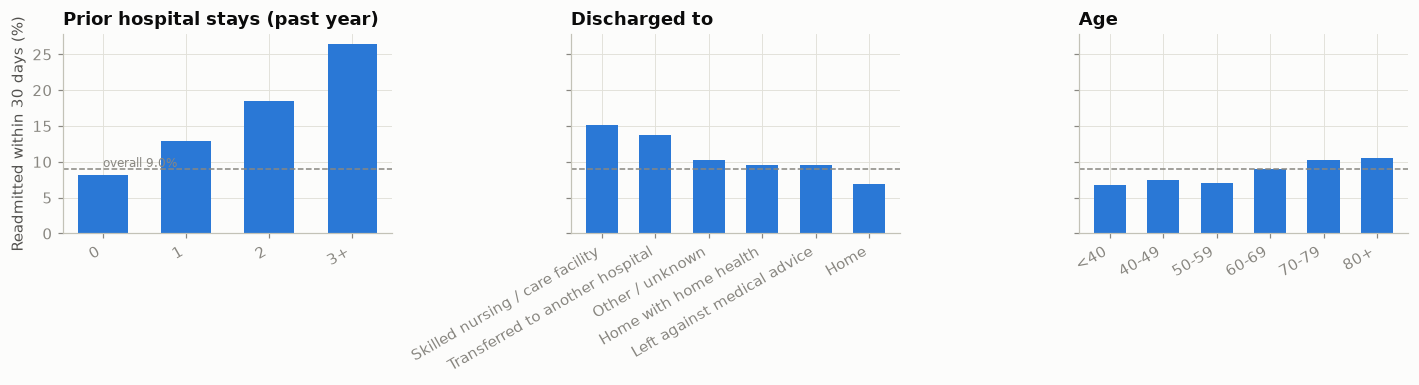

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, name in zip(axes, ["Prior hospital stays (past year)", "Discharged to", "Age"]):
    d = dims[name]
    ax.bar(d.level.astype(str), d.readmit_pct, color=SERIES[0], width=0.6)
    ax.axhline(100 * BASE, color=MUTED, lw=1, ls="--")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)
    for lbl in ax.get_xticklabels(): lbl.set_ha("right")
axes[0].set_ylabel("Readmitted within 30 days (%)")
axes[0].text(0, 100 * BASE + 0.3, f"overall {100*BASE:.1f}%", color=MUTED, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "02_readmit_by_dim.png", dpi=160); plt.show()

## 2. Profile: who gets readmitted?

The same patients, side by side: readmitted within 30 days vs. not.

In [5]:
profile = con.sql('''
    SELECT CASE WHEN readmit_30 = 1 THEN 'Readmitted <30d' ELSE 'Not readmitted' END AS grp,
           COUNT(*) AS patients,
           ROUND(AVG(age_mid), 1) AS avg_age,
           ROUND(AVG(time_in_hospital), 1) AS avg_days,
           ROUND(AVG(num_medications), 1) AS avg_medications,
           ROUND(AVG(number_diagnoses), 1) AS avg_diagnoses,
           ROUND(100 * AVG(CAST(number_inpatient > 0 AS INT)), 1) AS pct_prior_stay,
           ROUND(100 * AVG(has_heart_dx), 1) AS pct_heart_dx,
           ROUND(100 * AVG(has_kidney_dx), 1) AS pct_kidney_dx,
           ROUND(100 * AVG(CAST(insulin <> 'No' AS INT)), 1) AS pct_insulin,
           ROUND(100 * AVG(CAST(discharge_to <> 'Home' AS INT)), 1) AS pct_not_home
    FROM p GROUP BY 1 ORDER BY 1 DESC
''').df().set_index("grp").T
profile

grp,Readmitted <30d,Not readmitted
patients,6285.0,63702.0
avg_age,67.8,65.2
avg_days,4.8,4.2
avg_medications,16.6,15.6
avg_diagnoses,7.5,7.2
pct_prior_stay,20.1,10.9
pct_heart_dx,61.1,57.9
pct_kidney_dx,13.4,10.1
pct_insulin,54.8,50.7
pct_not_home,51.0,35.3


## 3. The hospital journey

For each patient I follow four steps: **was blood sugar (A1C) checked → what did it show → were diabetes medications changed → readmitted within 30 days?**

Current guidelines say a diabetic patient admitted to hospital should get an A1C test if none was done in the past 3 months, and a high result should prompt a treatment change. This shows how often that happened.

In [6]:
p["a1c_step"] = np.select([p.A1Cresult == "Not tested", p.A1Cresult == "Norm"],
                          ["Not tested", "Tested: normal"], "Tested: high (>7%)")
p["med_step"] = np.where(p["change"] == "Ch", "Meds changed", "No change")
con.register("p", p)

journey = con.sql('''
    SELECT a1c_step, med_step, COUNT(*) AS patients,
           ROUND(100 * AVG(readmit_30), 1) AS readmit_pct
    FROM p GROUP BY 1, 2 ORDER BY 1, 2
''').df()
journey["pct_of_all"] = (100 * journey.patients / len(p)).round(1)
journey

,a1c_step,med_step,patients,readmit_pct,pct_of_all
0,Not tested,Meds changed,24414,9.7,34.9
1,Not tested,No change,32727,8.7,46.8
2,Tested: high (>7%),Meds changed,5473,8.6,7.8
3,Tested: high (>7%),No change,3632,7.8,5.2
4,Tested: normal,Meds changed,1608,8.6,2.3
5,Tested: normal,No change,2133,8.6,3.0


In [7]:
tested = (p.A1Cresult != "Not tested").mean()
high = p.A1Cresult.isin([">7", ">8"])
high_changed = (p.loc[high, "change"] == "Ch").mean()
print(f"A1C checked during the stay: {tested:.1%}")
print(f"High A1C patients whose diabetes meds were changed: {high_changed:.1%}")
print(f"High A1C patients left on the same meds: {1 - high_changed:.1%}")

A1C checked during the stay: 18.4%
High A1C patients whose diabetes meds were changed: 60.1%
High A1C patients left on the same meds: 39.9%


Only **18%** of patients had their A1C checked during the stay, and **4 in 10** of those with a high result went home on unchanged diabetes medication. Patients who were tested were readmitted slightly less often than those who weren't (about 8% vs. 9%). That's a correlation, not proof testing helps, since tested patients may differ in other ways. Either way, the bigger gap is **whether anyone looked**, not which drug was chosen.

## 4. What these patients were treated with (1999–2008)

Share of patients on each drug class during the stay, using the classes from the NLM RxClass API (notebook 01).

In [8]:
from src.classes import classes_of     # the same classifier notebook 02 uses for CMS drug names
DRUG_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide", "glipizide",
             "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol", "troglitazone",
             "tolazamide", "insulin", "glyburide-metformin", "glipizide-metformin", "glimepiride-pioglitazone",
             "metformin-rosiglitazone", "metformin-pioglitazone"]
col_classes = classes_of

classes = sorted({c for col in DRUG_COLS for c in col_classes(col)}, key=CLASS_ORDER.index)
for c in classes:
    cols = [col for col in DRUG_COLS if c in col_classes(col)]
    p["on_" + c] = (p[cols] != "No").any(axis=1).astype(int)

then = pd.DataFrame({c: [100 * p["on_" + c].mean()] for c in classes}, index=["% of patients"]).T.round(1)
then["% of heart-disease patients"] = [round(100 * p.loc[p.has_heart_dx == 1, "on_" + c].mean(), 1) for c in classes]
then

,% of patients,% of heart-disease patients
Biguanide (metformin),21.9,20.6
Sulfonylurea,29.7,32.3
Thiazolidinedione,14.1,14.7
Meglitinide,2.0,2.2
Alpha-glucosidase inhibitor,0.3,0.3
Insulin,51.0,48.8


In [9]:
heart = p.has_heart_dx.mean()
print(f"Patients with a heart / circulatory diagnosis: {heart:.1%}, readmitted {p.loc[p.has_heart_dx==1,'readmit_30'].mean():.1%}")
print(f"Patients with a kidney diagnosis: {p.has_kidney_dx.mean():.1%}, readmitted {p.loc[p.has_kidney_dx==1,'readmit_30'].mean():.1%}")

Patients with a heart / circulatory diagnosis: 58.2%, readmitted 9.4%
Patients with a kidney diagnosis: 10.4%, readmitted 11.6%


In 1999–2008, **none** of these patients were on a GLP-1 or SGLT2 drug, the two classes guidelines now recommend for diabetic patients with heart or kidney disease (the first GLP-1, exenatide, arrived in 2005 and the first SGLT2 in 2013). Treatment was insulin, sulfonylureas and metformin. Yet **58%** of patients had a heart or circulatory diagnosis and **10%** a kidney diagnosis (readmitted at 11.6%). Those patients are the ones whose recommended treatment has changed most since. Notebook 03 looks at those drugs today, and notebook 04 asks for which patients they pay for themselves.

# Readmission models

## 1. Features

Everything known **by discharge**: demographics, how the patient arrived, the stay itself (days, labs, procedures, medications), prior use of care, diagnoses, A1C and glucose results, the drug classes given, and where they were discharged to. The readmission outcome itself and IDs are excluded.

In [10]:
y = p.readmit_30.values
p["insulin_dose_changed"] = p.insulin.isin(["Up", "Down"]).astype(int)
p["meds_changed"] = (p["change"] == "Ch").astype(int)
p["on_diabetes_meds"] = (p.diabetesMed == "Yes").astype(int)
on_cols = [c for c in p.columns if c.startswith("on_")]

NUM = ["age_mid", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
       "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
       "has_heart_dx", "has_kidney_dx", "insulin_dose_changed", "meds_changed"] + on_cols
CAT = ["gender", "race", "admission_type", "admission_source", "discharge_to", "diag_1_group",
       "A1Cresult", "max_glu_serum", "specialty", "payer_code"]
X = p[NUM + CAT]

prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200, sparse_output=False), CAT),
])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"train {len(X_tr):,} / test {len(X_te):,}; {len(NUM)} numeric + {len(CAT)} categorical columns")

train 52,490 / test 17,497; 20 numeric + 10 categorical columns


## 2. Fit the three models

Readmissions are only ~9% of patients, so I weight the classes in training and judge the models on **ROC-AUC** (ranking quality), **PR-AUC** (precision on the rare class) and **top-decile lift**: how much more often readmission happens among the 10% of patients the model flags as highest risk. Lift is the number an outreach program actually uses.

In [11]:
models = {
    "Penalized logistic (L1)": LogisticRegressionCV(Cs=10, penalty="l1", solver="saga", scoring="roc_auc",
                                                    class_weight="balanced", max_iter=3000, cv=5, n_jobs=-1, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=25, max_features="sqrt",
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=42),
    "Neural network (MLP)": MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True,
                                          max_iter=300, random_state=42),
}

def top_decile_lift(y_true, score):
    cut = np.quantile(score, 0.9)
    return y_true[score >= cut].mean() / y_true.mean()

fitted, rows, scores = {}, [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(X_tr, y_tr)
    s = pipe.predict_proba(X_te)[:, 1]
    fitted[name], scores[name] = pipe, s
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y_te, s), "PR-AUC": average_precision_score(y_te, s),
                 "Top-decile lift": top_decile_lift(y_te, s)})
results = pd.DataFrame(rows).round(3)
results

,model,ROC-AUC,PR-AUC,Top-decile lift
0,Penalized logistic (L1),0.643,0.156,2.011
1,Random forest,0.656,0.163,2.317
2,Neural network (MLP),0.635,0.150,2.005


In [12]:
cv = StratifiedKFold(5, shuffle=True, random_state=7)
cv_auc = cross_val_score(Pipeline([("prep", prep), ("model", models["Random forest"])]), X, y, cv=cv,
                         scoring="roc_auc", n_jobs=-1)
print(f"Random forest 5-fold ROC-AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")
print(f"No-skill PR-AUC (base rate): {y_te.mean():.3f}")

Random forest 5-fold ROC-AUC: 0.656 ± 0.008
No-skill PR-AUC (base rate): 0.090


**Reading the results.** All three models land in a narrow range (ROC-AUC 0.64–0.66), in line with published work on this dataset. The neural network is the weakest of the three, so **more flexibility doesn't buy anything here**; the random forest is best by a small margin. Readmission depends a lot on what happens after discharge, which isn't in the hospital record. Still, the 10% of patients the random forest flags are readmitted at about **2.3×** the average rate, enough to focus a follow-up program.

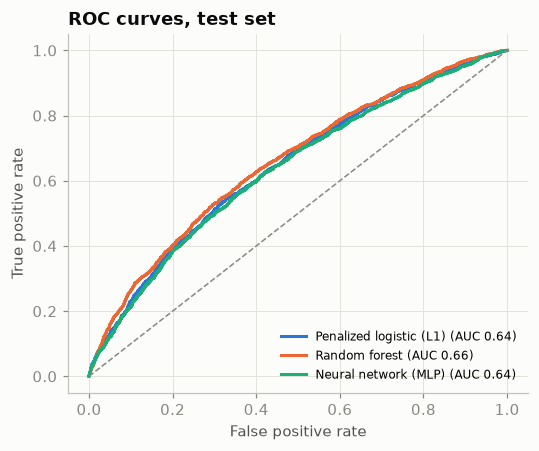

In [13]:
fig, ax = plt.subplots(figsize=(5, 4.2))
for i, (name, s) in enumerate(scores.items()):
    fpr, tpr, _ = roc_curve(y_te, s)
    ax.plot(fpr, tpr, color=SERIES[i], lw=2, label=f"{name} (AUC {roc_auc_score(y_te, s):.2f})")
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curves, test set")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIGURES / "02_roc.png", dpi=160); plt.show()

## 3. What drives the risk

Two views that should agree: the **lasso coefficients** (as odds ratios, holding everything else fixed) and **permutation importance** for the random forest (how much test AUC drops when a column is shuffled).

In [14]:
lasso = fitted["Penalized logistic (L1)"]
names = lasso.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lasso.named_steps["model"].coef_[0], index=names)
kept = (coef != 0).sum()
print(f"Lasso kept {kept} of {len(coef)} features (C = {lasso.named_steps['model'].C_[0]:.3g})")
odds = np.exp(coef[coef != 0]).sort_values()
odds_tbl = pd.concat([odds.head(6), odds.tail(10)]).rename("odds ratio per 1 SD / vs. baseline").round(2)
odds_tbl.index = odds_tbl.index.str.replace("num__", "").str.replace("cat__", "")
odds_tbl

Lasso kept 61 of 85 features (C = 0.0464)


discharge_to_Home                               0.69
specialty_Cardiology                            0.81
diag_1_group_Respiratory                        0.85
admission_source_Transfer                       0.89
specialty_Surgery                               0.90
specialty_Orthopedics                           0.90
A1Cresult_Not tested                            1.07
number_emergency                                1.08
specialty_Psychiatry                            1.09
on_diabetes_meds                                1.10
admission_source_Physician / clinic referral    1.10
diag_1_group_Circulatory                        1.15
payer_code_Unknown                              1.17
number_inpatient                                1.23
discharge_to_Transferred to another hospital    1.29
discharge_to_Skilled nursing / care facility    1.50
Name: odds ratio per 1 SD / vs. baseline, dtype: float64

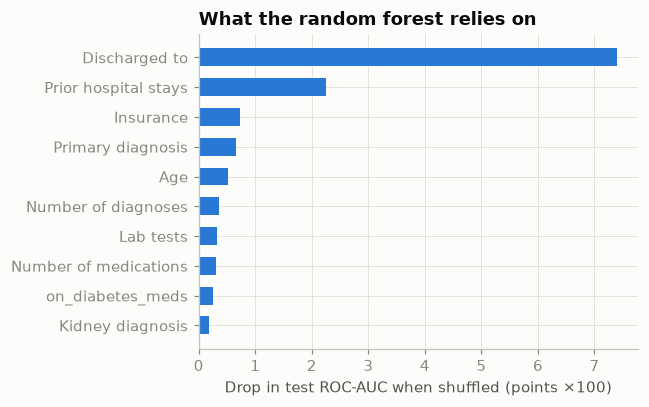

In [15]:
rf = fitted["Random forest"]
perm = permutation_importance(rf, X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_te.columns).sort_values(ascending=False)
top = imp.head(10)

LABEL = {"number_inpatient": "Prior hospital stays", "discharge_to": "Discharged to", "number_emergency": "Prior ER visits",
         "number_diagnoses": "Number of diagnoses", "time_in_hospital": "Days in hospital", "num_medications": "Number of medications",
         "diag_1_group": "Primary diagnosis", "age_mid": "Age", "number_outpatient": "Prior outpatient visits",
         "num_lab_procedures": "Lab tests", "admission_source": "Admitted from", "specialty": "Admitting specialty",
         "payer_code": "Insurance", "A1Cresult": "A1C result", "has_heart_dx": "Heart diagnosis", "num_procedures": "Procedures",
         "admission_type": "Admission type", "race": "Race", "has_kidney_dx": "Kidney diagnosis", "meds_changed": "Meds changed",
         "on_Insulin": "On insulin", "insulin_dose_changed": "Insulin dose changed", "max_glu_serum": "Glucose test"}
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.barh([LABEL.get(c, c) for c in top.index[::-1]], top.values[::-1] * 100, color=SERIES[0], height=0.6)
ax.set_xlabel("Drop in test ROC-AUC when shuffled (points ×100)"); ax.set_title("What the random forest relies on")
plt.tight_layout(); plt.savefig(FIGURES / "02_importance.png", dpi=160); plt.show()

## Score every patient for Part C

The value analysis (notebook 04) needs a risk score for **every** patient, not just the 25% test set. I use 5-fold out-of-fold predictions from the random forest: each patient is scored by a model that never saw them. Then I group patients into risk deciles and record, for each decile, how often they were in hospital in the past 12 months (this stay plus prior stays). That count is the input notebook 04 turns into dollars.

In [16]:
from sklearn.model_selection import cross_val_predict
rf_pipe = Pipeline([("prep", prep), ("model", models["Random forest"])])
p["risk_score"] = cross_val_predict(rf_pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=11),
                                    method="predict_proba", n_jobs=-1)[:, 1]
p["risk_decile"] = pd.qcut(p.risk_score.rank(method="first"), 10, labels=range(1, 11)).astype(int)
p["admits_past_12m"] = p.number_inpatient + 1          # this stay + prior stays in the past year
p["any_readmit"] = (p.readmitted != "NO").astype(int)
print(f"Out-of-fold ROC-AUC on all patients: {roc_auc_score(y, p.risk_score):.3f}")

risk_groups = (p.groupby("risk_decile")
                 .agg(patients=("readmit_30", "size"), readmit_30_pct=("readmit_30", "mean"), any_readmit_pct=("any_readmit", "mean"),
                      admits_past_12m=("admits_past_12m", "mean"), prior_stay_pct=("number_inpatient", lambda s: (s > 0).mean()),
                      heart_pct=("has_heart_dx", "mean"), kidney_pct=("has_kidney_dx", "mean"))
                 .assign(**{c: lambda d, c=c: (100 * d[c]).round(1) for c in ["readmit_30_pct", "any_readmit_pct", "prior_stay_pct", "heart_pct", "kidney_pct"]})
                 .round({"admits_past_12m": 2}))
p.to_parquet(PROCESSED / "patients_scored.parquet", index=False)
risk_groups

Out-of-fold ROC-AUC on all patients: 0.656


,patients,readmit_30_pct,any_readmit_pct,admits_past_12m,prior_stay_pct,heart_pct,kidney_pct
risk_decile,,,,,,,
1,6999,3.3,22.1,1.00,0.0,35.7,0.4
2,6999,5.1,30.2,1.00,0.2,50.3,2.2
3,6998,5.7,34.6,1.01,1.0,56.7,3.7
4,6999,6.4,38.3,1.02,2.0,60.6,7.6
5,6999,6.5,40.0,1.04,4.3,64.2,10.4
6,6998,8.4,42.3,1.09,8.4,64.8,14.0
7,6999,9.6,46.0,1.15,13.4,65.5,16.8
8,6998,11.0,49.2,1.24,20.4,62.6,17.6
9,6999,13.3,50.1,1.43,28.9,57.6,17.1


The top risk deciles are where repeat hospital use concentrates: patients there average well over one prior stay a year and come back far more often, both within 30 days and later. Risk is mostly **history**, which is exactly what makes those patients predictable enough to act on.

In [17]:
dec = pd.DataFrame({"y": y_te, "s": scores["Random forest"]})
dec["decile"] = pd.qcut(dec.s.rank(method="first"), 10, labels=range(1, 11)).astype(int)
deciles = (dec.groupby("decile").y.mean() * 100).round(1)
best = results.sort_values("ROC-AUC", ascending=False).iloc[0]

update_results("profile", {
    "overall_readmit": round(100 * BASE, 1),
    "by": {k: v[["level", "patients", "pct_of_patients", "readmit_pct"]].astype({"level": str}).to_dict("records") for k, v in dims.items()},
    "a1c_tested_pct": round(100 * tested, 1), "high_a1c_changed_pct": round(100 * high_changed, 1),
    "heart_dx_pct": round(100 * heart, 1), "kidney_dx_pct": round(100 * p.has_kidney_dx.mean(), 1),
    "classes_then": then.reset_index().rename(columns={"index": "drug_class"}).to_dict("records"),
})
update_results("models", {
    "comparison": results.to_dict("records"), "cv_auc_rf": [round(cv_auc.mean(), 3), round(cv_auc.std(), 3)],
    "base_rate": round(100 * y.mean(), 1), "lasso_kept": int(kept), "lasso_total": int(len(coef)),
    "importance": [{"feature": LABEL.get(k, k), "auc_drop": round(float(v), 4)} for k, v in top.items()],
    "deciles": [{"decile": int(k), "readmit_pct": float(v)} for k, v in deciles.items()],
    "best_model": best.model, "oof_auc": round(roc_auc_score(y, p.risk_score), 3),
    "risk_groups": risk_groups.reset_index().to_dict("records"),
})
print("saved")

saved
